## Step 1 - scRNA-seq data preparation

In [ ]:
import scanpy as sc
import pandas as pd
import sys
import numpy as np
import os
import seaborn as sns
import matplotlib.pyplot as plt
import anndata as ad
from pathlib import Path


In [ ]:
# --- Configuration ---
os.chdir('/home/kl467102/thesis')
tf_file = '/home/kl467102/Beeline-238/inputs/hHep/human-tfs.csv'
network_file = '/home/kl467102/string_dir/9606_protein_links_gene_names_combined_score_700.csv'
network_name = 'STRING12'
beeline_dir = '/home/kl467102/thesis/BEELINE/'
beeline_dir = Path(beeline_dir)

### Kim 23 data

In [ ]:
dataset_name = 'kim23-hm1'
prefix = 'GSM4832483_HM-1_'

# Number of highly variable genes to select
n_top_hvg = 2000
# Whether to include HV TFs in the analysis
include_hv_tfs = True
tfs_suffix = 'TFs' if include_hv_tfs else ''
# Directory to save the processed data
output_dir = beeline_dir / 'inputs' / dataset_name
param_prefix = output_dir / f"{dataset_name}_{network_name}_{n_top_hvg}{tfs_suffix}"

os.makedirs(output_dir, exist_ok=True)

### preprocessing

In [ ]:
# --- 1. Load Data ---
data_dir = '/home/ajank/sc_GRN_reconstruction/data/Kim2023'
adata_rna = sc.read_10x_mtx(data_dir, prefix=prefix)

print(f"Initial AnnData shape: {adata_rna.shape}") # (cells, genes)

print(f"Reading TF list: {tf_file}")
tfs_df = pd.read_csv(tf_file, header=0)
all_known_tfs = set(tfs_df[tfs_df.columns[0]])

print(f"Reading network: {network_file}")
net_df = pd.read_csv(network_file)
print(f"Initial network shape: {net_df.shape}")


Initial AnnData shape: (9988, 32738)
Reading TF list: /home/kl467102/Beeline-238/inputs/hHep/human-tfs.csv
Reading network: /home/kl467102/string_dir/9606_protein_links_gene_names_combined_score_700.csv
Initial network shape: (472000, 2)


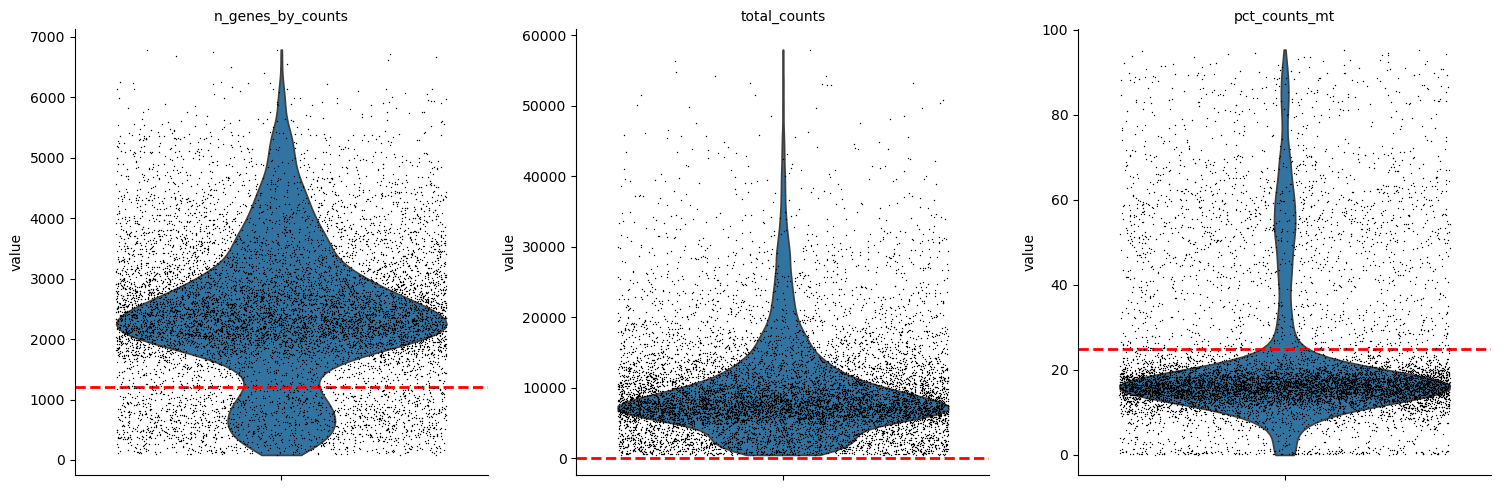

In [ ]:
## --- 2. Preprocess Data ---

# mitochondrial genes, "MT-" for human, "Mt-" for mouse
adata_rna.var["mt"] = adata_rna.var_names.str.startswith("MT-")
# ribosomal genes
adata_rna.var["ribo"] = adata_rna.var_names.str.startswith(("RPS", "RPL"))
# hemoglobin genes
adata_rna.var["hb"] = adata_rna.var_names.str.contains("^HB[^(P)]")

sc.pp.calculate_qc_metrics(
    adata_rna, qc_vars=["mt", "ribo", "hb"], inplace=True, log1p=True
)

fig = sc.pl.violin(
    adata_rna,
    ["n_genes_by_counts", "total_counts", "pct_counts_mt"],
    jitter=0.4,
    multi_panel=True,
    show=False 
)
min_genes = 1200
min_counts = 4000 if dataset_name == 'kim23-dm1' else 100
min_cells = 10
max_mt = 25

# Add horizontal lines to each subplot
axes = fig.axes.flat
lines = [min_genes, min_counts, max_mt] 

for ax, y in zip(axes, lines):
    ax.axhline(y, color='red', linestyle='--', linewidth=2)

plt.tight_layout()
plt.show()

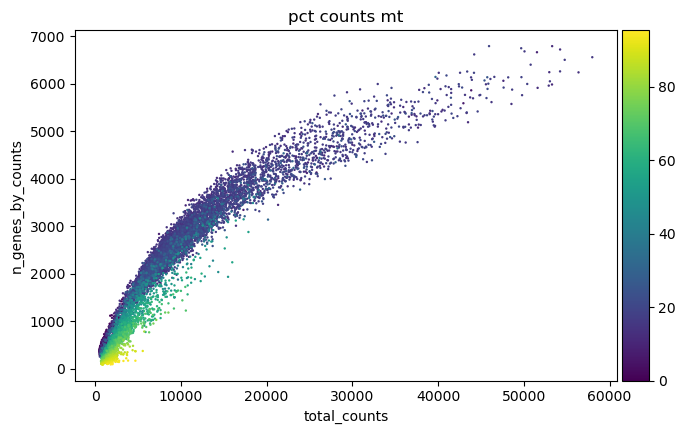

In [ ]:
sc.pl.scatter(adata_rna, "total_counts", "n_genes_by_counts", color="pct_counts_mt")

In [ ]:
# filtering

# # filter out cells with too few genes
sc.pp.filter_cells(adata_rna, min_genes=min_genes)
sc.pp.filter_cells(adata_rna, min_counts=min_counts)

# filter out genes with low expression
sc.pp.filter_genes(adata_rna, min_cells=min_cells)

# filter out cells with high mitochondrial content
adata_rna = adata_rna[adata_rna.obs.pct_counts_mt < max_mt, :]

# filter out mitochondrial genes
adata_rna = adata_rna[:, ~adata_rna.var.mt]

# # filter out ribosomal genes
# adata_rna = adata_rna[:, ~adata_rna.var.ribo]
# # filter out hemoglobin genes
# adata_rna = adata_rna[:, ~adata_rna.var.hb]

print(f"Filtered AnnData shape: {adata_rna.shape}") # (cells, genes)

Filtered AnnData shape: (7652, 16987)


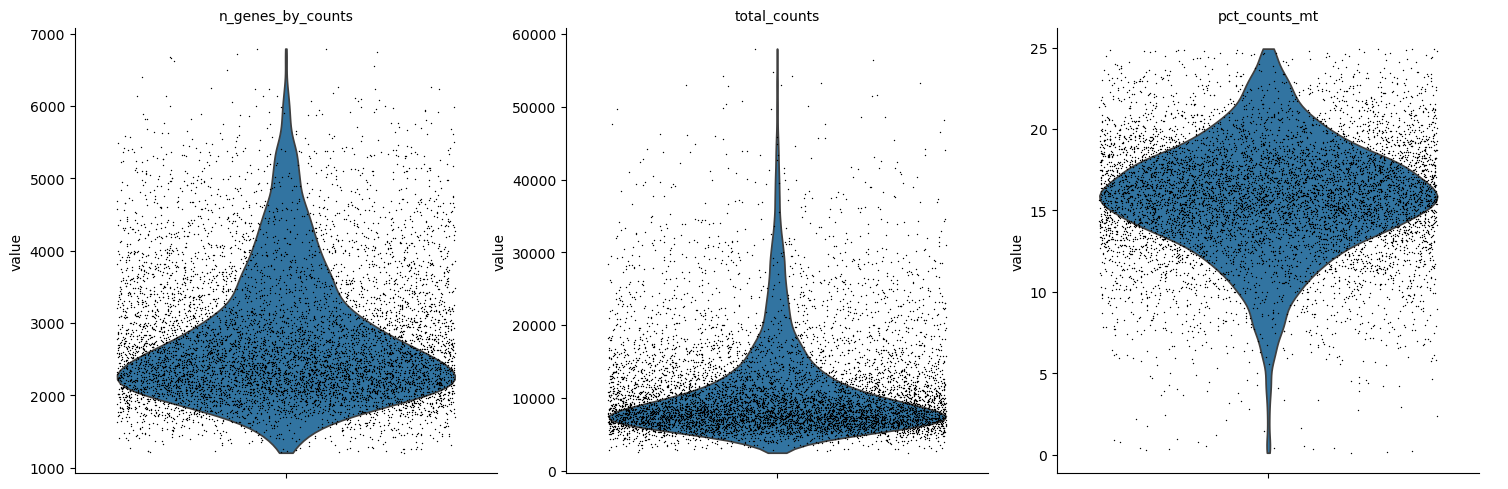

In [ ]:
sc.pl.violin(
    adata_rna,
    ["n_genes_by_counts", "total_counts", "pct_counts_mt"],
    jitter=0.4,
    multi_panel=True
    )


In [ ]:
# normalize and logarithmize
adata_rna.raw = adata_rna.copy()
adata_rna.layers['counts']=adata_rna.X.copy() 
sc.pp.normalize_total(adata_rna, target_sum=1e4)
sc.pp.log1p(adata_rna)
sc.pp.highly_variable_genes(adata_rna, n_top_genes=None)


In [ ]:
adata_rna

AnnData object with n_obs × n_vars = 7652 × 16987
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'n_genes', 'n_counts'
    var: 'gene_ids', 'feature_types', 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'log1p', 'hvg'
    layers: 'counts'

In [ ]:
sc.tl.pca(adata_rna)
sc.pp.neighbors(adata_rna)
sc.tl.umap(adata_rna)
sc.tl.leiden(adata_rna, flavor="igraph")


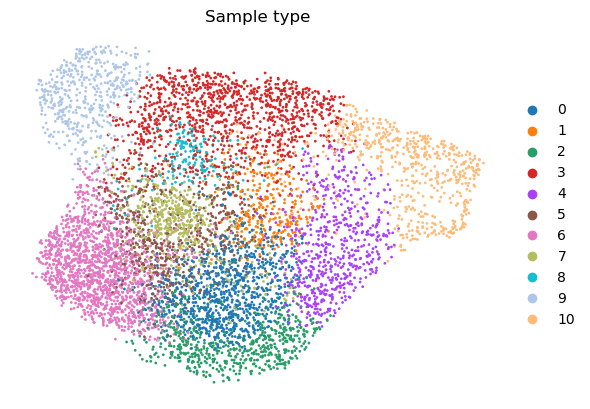

In [ ]:
sc.pl.umap(adata_rna, color="leiden", frameon=False,  title='Sample type')

In [17]:
adata_path = output_dir / f"{dataset_name}.h5ad"
adata_rna.write(adata_path)
print(f"Saved processed AnnData to {adata_path}")
adata_rna = sc.read(adata_path)

Saved processed AnnData to /home/kl467102/thesis/BEELINE/inputs/kim23-hm1/kim23-hm1.h5ad


### Preparing input for Beeline

In [18]:
genes_in_data = set(adata_rna.var_names)
tfs_in_data = all_known_tfs.intersection(genes_in_data)
print(f"Found {len(tfs_in_data)} TFs present in the expression data.")

Found 1265 TFs present in the expression data.


In [19]:
sc.pp.highly_variable_genes(adata_rna, n_top_genes=None)
default_mask = adata_rna.var['highly_variable'].copy()
n_default = default_mask.sum()
print(f"Default HVGs: {n_default}")
# Cutoff HVGs
sc.pp.highly_variable_genes(adata_rna, n_top_genes=n_top_hvg)
cutoff_mask = adata_rna.var['highly_variable'].copy()
n_cutoff = cutoff_mask.sum()
print(f"Top {n_top_hvg} HVGs: {n_cutoff}")
# Include TFs
tf_mask = adata_rna.var_names.isin(all_known_tfs)
tf_in_default = default_mask & tf_mask
n_tf_default = tf_in_default.sum()
print(f"TFs in default HVGs: {n_tf_default}")
combined = cutoff_mask.copy()
if include_hv_tfs:
    combined |= tf_in_default
    added = combined.sum() - n_cutoff
    print(f"Including additional {added} TFs → total combined HVGs: {combined.sum()}")



Default HVGs: 1372
Top 2000 HVGs: 2000
TFs in default HVGs: 133
Including additional 5 TFs → total combined HVGs: 2005


In [20]:
os.makedirs(param_prefix, exist_ok=True)

In [22]:
ad_hvg = adata_rna[:, combined].copy()
ad_hvg_path = param_prefix / f"adata.h5ad"
ad_hvg.write(ad_hvg_path)
ad_hvg = sc.read(ad_hvg_path)
expr_df = pd.DataFrame(
    ad_hvg.X.toarray(),
    index=ad_hvg.obs_names,
    columns=ad_hvg.var_names
).T
print(f"HVG subset shape: cells={ad_hvg.n_obs}, genes={ad_hvg.n_vars}\n")
    
    
filtered_net_df = net_df[
    net_df['Gene1'].isin(ad_hvg.var.index) &
    net_df['Gene2'].isin(ad_hvg.var.index)
].copy()
filtered_net_df = filtered_net_df[filtered_net_df['Gene1'] != filtered_net_df['Gene2']]
filtered_net_df.drop_duplicates(keep='first', inplace=True)
expr_file = param_prefix / 'ExpressionData.csv'
expr_df.to_csv(expr_file, index=True)
filtered_network_filename = param_prefix / 'refNetwork.csv'
filtered_net_df.to_csv(filtered_network_filename, index=False)

print(f"Saved filtered expression data to {expr_file}")
print(f"Saved filtered network to {filtered_network_filename}")


HVG subset shape: cells=7652, genes=2005

Saved filtered expression data to /home/kl467102/thesis/BEELINE/inputs/kim23-hm1/kim23-hm1_STRING12_2000TFs/ExpressionData.csv
Saved filtered network to /home/kl467102/thesis/BEELINE/inputs/kim23-hm1/kim23-hm1_STRING12_2000TFs/refNetwork.csv
